In [1]:
!pip install -q datasets seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [16]:
import numpy as np
import pandas as pd
import random
import math
import pickle
from collections import Counter, defaultdict
import os
import urllib
import zipfile
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from datasets import load_dataset
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score

random.seed(SEED)
np.random.seed(SEED)

In [3]:
#Loading the dataset
raw =load_dataset("eriktks/conll2003", revision="refs/convert/parquet")
print(raw)

conll2003/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

conll2003/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/312k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/283k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})


In [4]:
# Getting the ClassLabel from ner_tags
Labels = raw["train"].features["ner_tags"].feature.names
print("Total No of tags: ",len(Labels))
print(Labels)


Total No of tags:  9
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


In [36]:
# Loading the ClassLabel
NER_Feature = raw["train"].features["ner_tags"].feature

# Every sentence in data is converted to token and tag pairs
def pairing(split):
    sentences = []
    # grab stuff from raw
    for sen in raw[split]:
        tokens = list(sen["tokens"])
        tags = []
        for tag in sen["ner_tags"]:
            tags.append(NER_Feature.int2str(tag))
        sentences.append((tokens, tags))

    return sentences

splits_list = ["train", "validation", "test"]
data = {}
for s in splits_list:
    data[s] = pairing(s)

In [38]:
train_vocab = Counter([w for tok, _ in data["train"] for w in tok])
# quick check on test oov
test_words = [w for tok, _ in data["test"] for w in tok]
print("train vocab size:", len(train_vocab))

oov_count = 0
for w in test_words:
    if w not in train_vocab:
        oov_count += 1
print(f"Total no of out of vocabulary words is:{oov_count}")

train vocab size: 23623
Total no of out of vocabulary words is:5656


In [41]:
# from google.colab import drive
# drive.mount('/content/drive')
FILE_DIR = "."          # e.g. "/content/drive/MyDrive"

TASK1_PATH = os.path.join(FILE_DIR, "task1_hmm.pkl")
TASK2_PATH = os.path.join(FILE_DIR, "task2_bilstm_crf.pt")
TASK2_RESULTS = os.path.join(FILE_DIR, "task2_results.json")

for p in [TASK1_PATH, TASK2_PATH, TASK2_RESULTS]:
    print(f"{p:45s} {'found' if os.path.exists(p) else 'MISSING'}")

if not os.path.exists(TASK2_PATH):
    raise FileNotFoundError("task2_bilstm_crf.pt is required - run the Task 2 notebook first "
                            "and upload the file here (or point FILE_DIR to Drive).")

./task1_hmm.pkl                               found
./task2_bilstm_crf.pt                         found
./task2_results.json                          found


In [45]:
def hmm_transitions(sentences, labels, lam=0.1):
    # identical to HMMTagger.fit in Task 1 (transition part only)
    T = len(labels)
    tag2id = {t: i for i, t in enumerate(labels)}
    counts = np.zeros((T + 1, T + 1))
    for _, tags in sentences:
        prev = T                                    # START row
        for t in tags:
            counts[prev, tag2id[t]] += 1
            prev = tag2id[t]
        counts[prev, T] += 1                        # STOP column
    prob = (counts + lam) / (counts.sum(axis=1, keepdims=True) + lam * (T + 1))
    return np.log(prob[T, :T]), np.log(prob[:T, :T]), np.log(prob[:T, T])

task1_results = None
if os.path.exists(TASK1_PATH):
    with open(TASK1_PATH, "rb") as fh:
        t1 = pickle.load(fh)
    assert list(t1["labels"]) == list(Labels), "Task 1 label order differs"
    log_start, log_trans, log_stop = t1["log_start"], t1["log_trans"], t1["log_stop"]
    task1_results = t1["task1_results"]
    print("Loaded transitions from task1_hmm.pkl")
else:
    log_start, log_trans, log_stop = hmm_transitions(data["train"], Labels)
    print("task1_hmm.pkl not found - recomputed the same transitions from train")

# Tag prior P(t) from the training tokens - needed to turn P(t | x) into a scaled likelihood
tag_counts = Counter(t for _, tags in data["train"] for t in tags)
log_prior = np.log(np.array([tag_counts[t] for t in Labels], dtype=float) / sum(tag_counts.values()))

print(pd.DataFrame(np.exp(log_trans), index=Labels, columns=Labels).round(3))

Loaded transitions from task1_hmm.pkl
            O  B-PER  I-PER  B-ORG  I-ORG  B-LOC  I-LOC  B-MISC  I-MISC
O       0.819  0.031  0.000  0.022  0.000  0.033  0.000   0.017   0.000
B-PER   0.340  0.000  0.649  0.000  0.000  0.000  0.000   0.000   0.000
I-PER   0.907  0.000  0.054  0.000  0.000  0.000  0.000   0.000   0.000
B-ORG   0.586  0.000  0.000  0.003  0.393  0.000  0.000   0.001   0.000
I-ORG   0.648  0.001  0.000  0.002  0.329  0.000  0.000   0.001   0.000
B-LOC   0.832  0.000  0.000  0.001  0.000  0.001  0.146   0.004   0.000
I-LOC   0.850  0.000  0.000  0.001  0.000  0.003  0.100   0.003   0.000
B-MISC  0.706  0.017  0.000  0.009  0.000  0.002  0.000   0.009   0.250
I-MISC  0.627  0.003  0.000  0.006  0.000  0.002  0.000   0.004   0.257


In [11]:
class CharWordEncoder(nn.Module):
    def __init__(self, n_words, n_chars, n_tags, emb_matrix,
                 char_dim=25, char_hidden=25, word_hidden=100, dropout=0.5):
        super().__init__()
        self.char_emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.char_lstm = nn.LSTM(char_dim, char_hidden, batch_first=True, bidirectional=True)
        self.word_emb = nn.Embedding(n_words, emb_matrix.shape[1], padding_idx=0)
        self.word_emb.weight.data.copy_(torch.from_numpy(emb_matrix))
        self.dropout = nn.Dropout(dropout)
        self.word_lstm = nn.LSTM(emb_matrix.shape[1] + 2 * char_hidden, word_hidden,
                                 num_layers=1, batch_first=True, bidirectional=True)
        self.to_tags = nn.Linear(2 * word_hidden, n_tags)

    def char_features(self, chars):
        B, L, C = chars.shape
        flat = chars.view(B * L, C)
        lengths = (flat != 0).sum(1)
        real = lengths > 0
        out = torch.zeros(B * L, 2 * self.char_lstm.hidden_size, device=chars.device)
        packed = pack_padded_sequence(self.char_emb(flat[real]), lengths[real].cpu(),
                                      batch_first=True, enforce_sorted=False)
        _, (h, _) = self.char_lstm(packed)
        out[real] = torch.cat([h[0], h[1]], dim=1)
        return out.view(B, L, -1)

    def forward(self, words, chars, mask):
        x = torch.cat([self.word_emb(words), self.char_features(chars)], dim=2)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.word_lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=words.size(1))
        return self.to_tags(out)       # (B, L, n_tags) logits -> softmax gives P(tag | sentence, position)


# weights_only=False because the checkpoint also stores the vocabularies and a numpy matrix
ckpt = torch.load(TASK2_PATH, map_location="cpu", weights_only=False)
assert list(ckpt["labels"]) == list(L), "Task 2 label order differs"
word2id, char2id, tag2id = ckpt["word2id"], ckpt["char2id"], ckpt["tag2id"]
emb_matrix = ckpt["emb_matrix"]

encoder = CharWordEncoder(len(word2id), len(char2id), len(LABELS), emb_matrix)
enc_state = {k[len("encoder."):]: v for k, v in ckpt["model_state"].items() if k.startswith("encoder.")}
encoder.load_state_dict(enc_state)
encoder.to(device)
print(f"Loaded {len(enc_state)} encoder tensors from Task 2 (CRF weights left out)")

Loaded 20 encoder tensors from Task 2 (CRF weights left out)


In [12]:
PAD, UNK = "<PAD>", "<UNK>"

def norm(word):
    return "".join("0" if ch.isdigit() else ch for ch in word.lower())

def encode(tokens, tags):
    w = [word2id.get(norm(t), word2id[UNK]) for t in tokens]
    c = [[char2id.get(ch, char2id[UNK]) for ch in t] for t in tokens]
    y = [tag2id[t] for t in tags]
    return w, c, y

encoded = {split: [encode(*s) for s in sents] for split, sents in data.items()}

train_word_freq = Counter(norm(w) for toks, _ in data["train"] for w in toks)
singletons = {word2id[w] for w, c in train_word_freq.items() if c == 1 and w in word2id}

def make_batch(examples, train=False):
    B = len(examples)
    max_len = max(len(w) for w, _, _ in examples)
    max_chr = max(len(cw) for _, c, _ in examples for cw in c)
    words = torch.zeros(B, max_len, dtype=torch.long)
    chars = torch.zeros(B, max_len, max_chr, dtype=torch.long)
    tags = torch.zeros(B, max_len, dtype=torch.long)
    mask = torch.zeros(B, max_len, dtype=torch.bool)
    for b, (w, c, y) in enumerate(examples):
        if train:
            w = [word2id[UNK] if (i in singletons and random.random() < 0.5) else i for i in w]
        words[b, :len(w)] = torch.tensor(w)
        tags[b, :len(y)] = torch.tensor(y)
        mask[b, :len(w)] = True
        for j, cw in enumerate(c):
            chars[b, j, :len(cw)] = torch.tensor(cw)
    return words.to(device), chars.to(device), tags.to(device), mask.to(device)

In [17]:
BATCH_SIZE, MAX_EPOCHS, PATIENCE = 10, 30, 5
LR0, DECAY, MOMENTUM, CLIP = 0.015, 0.05, 0.9, 5.0
optimizer = torch.optim.SGD(encoder.parameters(), lr=LR0, momentum=MOMENTUM)

def token_ce(logits, tags, mask, temperature=1.0):
    return F.cross_entropy(logits[mask] / temperature, tags[mask])

@torch.no_grad()
def collect_logits(split, batch_size=64):
    # returns a list of (n_tokens, n_tags) logit arrays, one per sentence, plus the gold ids
    encoder.eval()
    out, gold = [], []
    exs = encoded[split]
    for s in range(0, len(exs), batch_size):
        words, chars, tags, mask = make_batch(exs[s:s + batch_size])
        logits = encoder(words, chars, mask).cpu()
        for b, n in enumerate(mask.sum(1).tolist()):
            out.append(logits[b, :n].numpy())
            gold.append(tags[b, :n].cpu().numpy())
    return out, gold

def log_loss_and_acc(logit_list, gold_list, temperature=1.0):
    z = torch.from_numpy(np.concatenate(logit_list))
    y = torch.from_numpy(np.concatenate(gold_list)).long()
    nll = F.cross_entropy(z / temperature, y).item()
    acc = (z.argmax(1) == y).float().mean().item()
    return nll, acc

dev_logits, dev_gold = collect_logits("validation")
nll0, acc0 = log_loss_and_acc(dev_logits, dev_gold)
print(f"Before fine-tuning (raw CRF emission scores through a softmax): dev log-loss {nll0:.4f}, token acc {acc0:.4f}")

Before fine-tuning (raw CRF emission scores through a softmax): dev log-loss 0.1304, token acc 0.9593


In [19]:
import time

In [20]:
history = []
best_nll, best_epoch, bad = float("inf"), 0, 0
best_state = {k: v.detach().cpu().clone() for k, v in encoder.state_dict().items()}

for epoch in range(MAX_EPOCHS):
    lr = LR0 / (1 + DECAY * epoch)
    for g in optimizer.param_groups:
        g["lr"] = lr

    encoder.train()
    order = list(range(len(encoded["train"])))
    random.shuffle(order)
    total, start = 0.0, time.time()
    for s in range(0, len(order), BATCH_SIZE):
        words, chars, tags, mask = make_batch([encoded["train"][i] for i in order[s:s + BATCH_SIZE]], train=True)
        optimizer.zero_grad()
        loss = token_ce(encoder(words, chars, mask), tags, mask)
        loss.backward()
        nn.utils.clip_grad_norm_(encoder.parameters(), CLIP)
        optimizer.step()
        total += loss.item()

    dev_logits, dev_gold = collect_logits("validation")
    nll, acc = log_loss_and_acc(dev_logits, dev_gold)
    history.append({"epoch": epoch + 1, "lr": lr, "train_ce": total / math.ceil(len(order) / BATCH_SIZE),
                    "dev_nll": nll, "dev_acc": acc})
    print(f"epoch {epoch + 1:2d} | lr {lr:.5f} | train CE {history[-1]['train_ce']:.4f} "
          f"| dev log-loss {nll:.4f} | dev token acc {acc:.4f} | {time.time() - start:5.1f}s")

    if nll < best_nll:
        best_nll, best_epoch, bad = nll, epoch + 1, 0
        best_state = {k: v.detach().cpu().clone() for k, v in encoder.state_dict().items()}
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"No improvement for {PATIENCE} epochs - stopping early.")
            break

encoder.load_state_dict(best_state)
print(f"\nBest dev log-loss {best_nll:.4f} at epoch {best_epoch}")

epoch  1 | lr 0.01500 | train CE 0.0738 | dev log-loss 0.0679 | dev token acc 0.9816 |  24.7s
epoch  2 | lr 0.01429 | train CE 0.0498 | dev log-loss 0.0600 | dev token acc 0.9842 |  25.7s
epoch  3 | lr 0.01364 | train CE 0.0428 | dev log-loss 0.0563 | dev token acc 0.9850 |  24.1s
epoch  4 | lr 0.01304 | train CE 0.0373 | dev log-loss 0.0548 | dev token acc 0.9855 |  23.8s
epoch  5 | lr 0.01250 | train CE 0.0349 | dev log-loss 0.0534 | dev token acc 0.9861 |  24.4s
epoch  6 | lr 0.01200 | train CE 0.0329 | dev log-loss 0.0526 | dev token acc 0.9863 |  23.6s
epoch  7 | lr 0.01154 | train CE 0.0308 | dev log-loss 0.0513 | dev token acc 0.9867 |  23.3s
epoch  8 | lr 0.01111 | train CE 0.0302 | dev log-loss 0.0516 | dev token acc 0.9869 |  24.1s
epoch  9 | lr 0.01071 | train CE 0.0292 | dev log-loss 0.0512 | dev token acc 0.9870 |  24.1s
epoch 10 | lr 0.01034 | train CE 0.0285 | dev log-loss 0.0512 | dev token acc 0.9868 |  22.9s
epoch 11 | lr 0.01000 | train CE 0.0274 | dev log-loss 0.050

In [21]:
def ece(logit_list, gold_list, temperature=1.0, n_bins=15):
    z = torch.from_numpy(np.concatenate(logit_list)) / temperature
    y = torch.from_numpy(np.concatenate(gold_list)).long()
    probs = z.softmax(1)
    conf, pred = probs.max(1)
    correct = (pred == y).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    total, bins = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        inb = (conf > lo) & (conf <= hi)
        if inb.any():
            gap = (correct[inb].mean() - conf[inb].mean()).abs().item()
            total += inb.float().mean().item() * gap
            bins.append((conf[inb].mean().item(), correct[inb].mean().item(), int(inb.sum())))
    return total, bins

def fit_temperature(logit_list, gold_list):
    z = torch.from_numpy(np.concatenate(logit_list))
    y = torch.from_numpy(np.concatenate(gold_list)).long()
    log_t = torch.zeros(1, requires_grad=True)             # optimise log T so T stays positive
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(z / log_t.exp(), y)
        loss.backward()
        return loss
    opt.step(closure)
    return log_t.exp().item()

dev_logits, dev_gold = collect_logits("validation")
TEMP = fit_temperature(dev_logits, dev_gold)

ece_before, bins_before = ece(dev_logits, dev_gold, 1.0)
ece_after, bins_after = ece(dev_logits, dev_gold, TEMP)
print(f"Fitted temperature T = {TEMP:.3f}")
print(f"Dev log-loss : {log_loss_and_acc(dev_logits, dev_gold, 1.0)[0]:.4f} -> {log_loss_and_acc(dev_logits, dev_gold, TEMP)[0]:.4f}")
print(f"Dev ECE      : {ece_before:.4f} -> {ece_after:.4f}")

Fitted temperature T = 1.385
Dev log-loss : 0.0497 -> 0.0450
Dev ECE      : 0.0047 -> 0.0010


In [24]:
import matplotlib.pyplot as plt

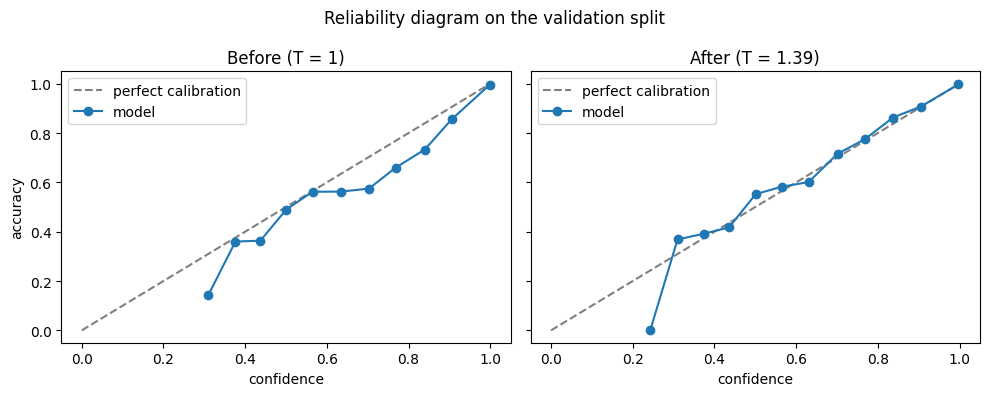

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, bins, title in [(axes[0], bins_before, "Before (T = 1)"), (axes[1], bins_after, f"After (T = {TEMP:.2f})")]:
    ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
    ax.plot([b[0] for b in bins], [b[1] for b in bins], marker="o", label="model")
    ax.set_title(title); ax.set_xlabel("confidence"); ax.legend(loc="upper left")
axes[0].set_ylabel("accuracy")
plt.suptitle("Reliability diagram on the validation split")
plt.tight_layout()
plt.savefig("task3_reliability.png", dpi=150)
plt.show()

In [28]:
def viterbi(emit, log_start=log_start, log_trans=log_trans, log_stop=log_stop):
    # emit: (n, T) log emission scores. Same recurrence as Task 1's HMMTagger.viterbi
    n, T = emit.shape
    score = np.empty((n, T))
    back = np.zeros((n, T), dtype=int)
    score[0] = log_start + emit[0]
    for i in range(1, n):
        cand = score[i - 1][:, None] + log_trans
        back[i] = cand.argmax(axis=0)
        score[i] = cand.max(axis=0) + emit[i]
    best = [int((score[-1] + log_stop).argmax())]
    for i in range(n - 1, 0, -1):
        best.append(int(back[i, best[-1]]))
    return best[::-1]

def log_softmax_np(z, temperature):
    z = z / temperature
    z = z - z.max(axis=1, keepdims=True)
    return z - np.log(np.exp(z).sum(axis=1, keepdims=True))

def decode_split(logit_list, mode="hybrid", temperature=1.0, prior_weight=1.0):
    preds = []
    for z in logit_list:
        logp = log_softmax_np(z, temperature)                  # log P(t | x, i)
        if mode == "argmax":                                   # neural probabilities alone, no HMM
            path = logp.argmax(axis=1).tolist()
        else:                                                  # neural-emission HMM
            path = viterbi(logp - prior_weight * log_prior)
        preds.append([Labels[t] for t in path])
    return preds

def scores(gold, pred):
    return {"precision": precision_score(gold, pred), "recall": recall_score(gold, pred),
            "f1": f1_score(gold, pred)}

test_logits, _ = collect_logits("test")
dev_gold_tags = [tags for _, tags in data["validation"]]
test_gold_tags = [tags for _, tags in data["test"]]

In [29]:
dev_pred = decode_split(dev_logits, "hybrid", TEMP, 1.0)
test_pred = decode_split(test_logits, "hybrid", TEMP, 1.0)

main_dev, main_test = scores(dev_gold_tags, dev_pred), scores(test_gold_tags, test_pred)
print(f"Dev   entity F1 = {main_dev['f1']:.4f}")
print(f"Test  entity P = {main_test['precision']:.4f}  R = {main_test['recall']:.4f}  F1 = {main_test['f1']:.4f}")
print(classification_report(test_gold_tags, test_pred, digits=4))

Dev   entity F1 = 0.9196
Test  entity P = 0.8763  R = 0.8706  F1 = 0.8734
              precision    recall  f1-score   support

         LOC     0.9132    0.9149    0.9140      1668
        MISC     0.7089    0.7251    0.7169       702
         ORG     0.8275    0.8200    0.8237      1661
         PER     0.9645    0.9400    0.9521      1617

   micro avg     0.8763    0.8706    0.8734      5648
   macro avg     0.8535    0.8500    0.8517      5648
weighted avg     0.8773    0.8706    0.8739      5648



In [32]:
variants = {
    "Softmax argmax (no HMM)":        dict(mode="argmax", temperature=TEMP),
    "Hybrid, no prior division":      dict(mode="hybrid", temperature=TEMP, prior_weight=0.0),
    "Hybrid, uncalibrated (T = 1)":   dict(mode="hybrid", temperature=1.0, prior_weight=1.0),
    "Hybrid (main)":                  dict(mode="hybrid", temperature=TEMP, prior_weight=1.0),
}

# beta sweep on the validation split only
sweep = {}
for beta in [0.0, 0.25, 0.5, 0.75, 1.0]:
    sweep[beta] = f1_score(dev_gold_tags, decode_split(dev_logits, "hybrid", TEMP, beta))
    print(f"prior weight beta = {beta:4.2f}  dev F1 = {sweep[beta]:.4f}")
BEST_BETA = max(sweep, key=sweep.get)
variants[f"Hybrid, beta = {BEST_BETA} (dev-tuned)"] = dict(mode="hybrid", temperature=TEMP, prior_weight=BEST_BETA)

ablation_rows, ablation_preds = [], {}
for name, kw in variants.items():
    d = scores(dev_gold_tags, decode_split(dev_logits, **kw))
    p = decode_split(test_logits, **kw)
    t = scores(test_gold_tags, p)
    ablation_preds[name] = p
    ablation_rows.append({"variant": name, "dev F1": d["f1"], "test P": t["precision"],
                          "test R": t["recall"], "test F1": t["f1"]})
ablation_df = pd.DataFrame(ablation_rows).set_index("variant")
display(ablation_df.round(4))

prior weight beta = 0.00  dev F1 = 0.9355
prior weight beta = 0.25  dev F1 = 0.9393
prior weight beta = 0.50  dev F1 = 0.9359
prior weight beta = 0.75  dev F1 = 0.9301
prior weight beta = 1.00  dev F1 = 0.9196


,dev F1,test P,test R,test F1
variant,,,,
Softmax argmax (no HMM),0.9223,0.8674,0.8955,0.8813
"Hybrid, no prior division",0.9355,0.9222,0.8725,0.8967
"Hybrid, uncalibrated (T = 1)",0.9303,0.8924,0.8899,0.8911
Hybrid (main),0.9196,0.8763,0.8706,0.8734
"Hybrid, beta = 0.25 (dev-tuned)",0.9393,0.9168,0.8842,0.9002


In [33]:
rows = []
if task1_results is not None:
    rows.append({"model": "Task 1 - HMM (counted emissions) + Viterbi", **{k: task1_results[k] for k in ["precision", "recall", "f1"]}})
if os.path.exists(TASK2_RESULTS):
    with open(TASK2_RESULTS) as fh:
        t2 = json.load(fh)
    rows.append({"model": "Task 2 - BiLSTM-CRF", **{k: t2[k] for k in ["precision", "recall", "f1"]}})
rows.append({"model": "Task 3 - Neural-emission HMM (main)", **main_test})
tuned_name = f"Hybrid, beta = {BEST_BETA} (dev-tuned)"
rows.append({"model": f"Task 3 - Neural-emission HMM, beta = {BEST_BETA}",
             "precision": ablation_df.loc[tuned_name, "test P"], "recall": ablation_df.loc[tuned_name, "test R"],
             "f1": ablation_df.loc[tuned_name, "test F1"]})

comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(4))
comparison.to_csv("task1_vs_task2_vs_task3.csv")

if task1_results is not None and os.path.exists(TASK2_RESULTS):
    f1_1, f1_2, f1_3 = task1_results["f1"], t2["f1"], main_test["f1"]
    if f1_2 > f1_1:
        print(f"\nShare of the Task 1 -> Task 2 gap closed by Task 3: {100 * (f1_3 - f1_1) / (f1_2 - f1_1):.1f}%")

,precision,recall,f1
model,,,
Task 1 - HMM (counted emissions) + Viterbi,0.6885,0.6843,0.6864
Task 2 - BiLSTM-CRF,0.9093,0.9102,0.9098
Task 3 - Neural-emission HMM (main),0.8763,0.8706,0.8734
"Task 3 - Neural-emission HMM, beta = 0.25",0.9168,0.8842,0.9002



Share of the Task 1 -> Task 2 gap closed by Task 3: 83.7%


In [35]:
torch.save({"encoder_state": encoder.state_dict(), "temperature": TEMP, "best_beta": BEST_BETA,
            "word2id": word2id, "char2id": char2id, "labels": Labels}, "task3_neural_hmm.pt")
with open("task3_results.json", "w") as fh:
    json.dump({"main_test": main_test, "main_dev": main_dev, "temperature": TEMP,
               "ece_dev_before": ece_before, "ece_dev_after": ece_after,
               "best_epoch": best_epoch, "history": history,
               "beta_sweep_dev": {str(k): v for k, v in sweep.items()},
               "ablations": ablation_df.reset_index().to_dict(orient="records")}, fh, indent=2)
print("Saved task3_neural_hmm.pt, task3_results.json, task1_vs_task2_vs_task3.csv and the plots")
print(f"TASK 3 RESULT -> test entity-level F1 = {main_test['f1']:.4f}")

# Optional: copy everything to Drive
# !cp task3_* task1_vs_task2_vs_task3.csv /content/drive/MyDrive/

Saved task3_neural_hmm.pt, task3_results.json, task1_vs_task2_vs_task3.csv and the plots
TASK 3 RESULT -> test entity-level F1 = 0.8734
